# Álvaro AI — Entrega 2: avaliação do RAG e do gatilho de abstenção

**FECAP · Inteligência Artificial e Aprendizagem de Máquina · 5º semestre (2026)**  
**Grupo:** Esther Oliveira Costa, Higor Fonseca e João Victor Faria  
**Agente avaliado:** exclusivamente **Álvaro AI — Agente para o Estudante**.

> **Atenção:** este notebook usa por padrão documentos e perguntas **fictícios** para validar o código. Os resultados exibidos **não** são métricas oficiais do Álvaro AI nem resultados da base de conhecimento da FECAP. Para a entrega acadêmica final, substitua pelos dados autorizados e rotulados do sistema real.

A comparação utiliza **quatro configurações de recuperação**: lexical aproximada, TF-IDF palavras, TF-IDF caracteres e híbrido lexical + caracteres. A baseline exata do TypeScript pode ser avaliada separadamente, conforme instruções do README.

## 1. Protocolo

- Unidade de avaliação: uma pergunta validada, com documento esperado ou indicação de **abstenção**.
- A lista de documentos da base constitui o corpus; **não** é um dataset de rótulos de treinamento.
- Separação determinística: **65% validação** para escolha do limiar; **35% teste retido** para apresentação final. Para corpus real, prefira divisão temporal e duplicatas de perguntas agrupadas por intenção.
- Medidas de busca: **Hit@1, Hit@3, MRR@3, nDCG@3**.
- Gatilho de abstenção: **precisão, recall, F1** e taxa de resposta indevida sem evidência. O limiar é otimizado por **F2 de abstenção na validação** (mais peso ao recall).
- **Não mede** automaticamente groundedness, correção de resposta ou FCR: isso exige respostas geradas, fontes e revisão humana.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt

# Funciona tanto se o notebook for aberto na raiz quanto na subpasta notebooks.
HERE = Path.cwd()
ROOT = HERE if (HERE / 'avaliacao' / 'avaliar_rag.py').exists() else HERE.parent
assert (ROOT / 'avaliacao' / 'avaliar_rag.py').exists(), 'Abra o notebook dentro do pacote Entrega2_AlvaroAI.'
KB = ROOT / 'avaliacao' / 'documentos_ficticios.json'
QUESTIONS = ROOT / 'avaliacao' / 'perguntas_ficticias.csv'
OUTPUT = ROOT / 'resultados_demo' / 'notebook_ficticio'
print('Base selecionada (FICTÍCIA):', KB)
print('Perguntas selecionadas:', QUESTIONS)

Base selecionada (FICTÍCIA): /mnt/data/Entrega2_AlvaroAI_Versao_Final/avaliacao/documentos_ficticios.json
Perguntas selecionadas: /mnt/data/Entrega2_AlvaroAI_Versao_Final/avaliacao/perguntas_ficticias.csv


## 2. Executar comparação reproduzível

Para avaliar a base **real autorizada**, altere `KB` e `QUESTIONS` acima para arquivos locais preparados e rotulados. Não comite documentos internos ou conversas privadas no GitHub.

In [2]:
run = subprocess.run([sys.executable, str(ROOT / 'avaliacao' / 'avaliar_rag.py'), '--kb', str(KB), '--questions', str(QUESTIONS), '--out', str(OUTPUT)], capture_output=True, text=True, check=True)
print(run.stdout)

              metodo  limiar_validado    hit_1  hit_3   mrr_3   ndcg_3  n  cobertura_resposta  precisao_abstencao  recall_abstencao  f1_abstencao  taxa_resposta_sem_evidencia
  lexical_aproximado         0.192500 0.777778    1.0 0.87037 0.903437 13            0.461538            0.571429              1.00      0.727273                     0.000000
      tfidf_palavras         0.172224 1.000000    1.0 1.00000 1.000000 13            0.461538            0.571429              1.00      0.727273                     0.000000
    tfidf_caracteres         0.167066 1.000000    1.0 1.00000 1.000000 13            0.769231            1.000000              0.75      0.857143                     0.076923
hibrido_lexical_char         0.175089 1.000000    1.0 1.00000 1.000000 13            0.692308            1.000000              1.00      1.000000                     0.000000
Saídas em /mnt/data/Entrega2_AlvaroAI_Versao_Final/resultados_demo/notebook_ficticio | corpus hash: 88b29f62628c



In [3]:
comparacao = pd.read_csv(OUTPUT / 'comparacao_teste.csv')
display(comparacao.round(3))

,metodo,limiar_validado,hit_1,hit_3,mrr_3,ndcg_3,n,cobertura_resposta,precisao_abstencao,recall_abstencao,f1_abstencao,taxa_resposta_sem_evidencia
0,lexical_aproximado,0.192,0.778,1.0,0.87,0.903,13,0.462,0.571,1.00,0.727,0.000
1,tfidf_palavras,0.172,1.000,1.0,1.00,1.000,13,0.462,0.571,1.00,0.727,0.000
2,tfidf_caracteres,0.167,1.000,1.0,1.00,1.000,13,0.769,1.000,0.75,0.857,0.077
3,hibrido_lexical_char,0.175,1.000,1.0,1.00,1.000,13,0.692,1.000,1.00,1.000,0.000


## 3. Visualizar ranking e abstenção

Os gráficos abaixo são **apenas ilustrativos** enquanto estiverem conectados à base fictícia.

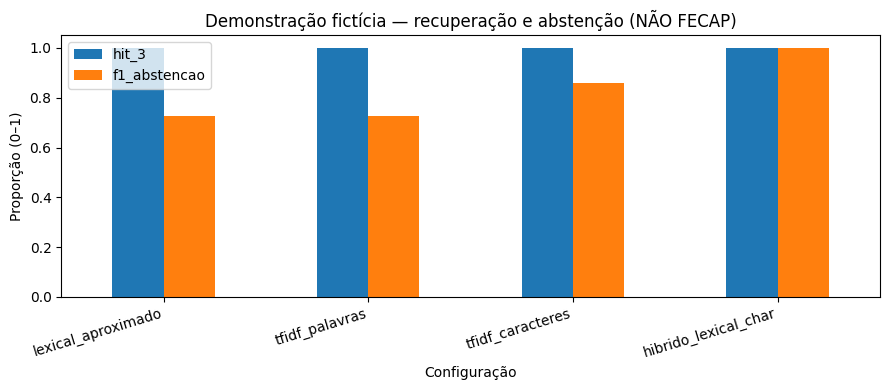

In [4]:
fig, ax = plt.subplots(figsize=(9,4))
comparacao.set_index('metodo')[['hit_3','f1_abstencao']].plot.bar(ax=ax)
ax.set_title('Demonstração fictícia — recuperação e abstenção (NÃO FECAP)')
ax.set_xlabel('Configuração')
ax.set_ylabel('Proporção (0–1)')
ax.set_ylim(0,1.05)
plt.xticks(rotation=17, ha='right')
plt.tight_layout()
plt.show()

## 4. Erros e evidências

O relatório CSV de cada configuração mostra: pergunta, documento esperado, top-3, decisão de abster e tipo de erro. Erros reais devem ser categorizados manualmente (paráfrase, fonte ausente, resposta sem evidência, documento desatualizado, ambiguidade, conflito).

In [5]:
erros = pd.read_csv(OUTPUT / 'erros_hibrido_lexical_char.csv')
display(erros[['qid','pergunta','doc_id_correto','ranking_ids','deve_abster','absteve','erro_retrieval_top3','resposta_sem_evidencia']].head(15))

,qid,pergunta,doc_id_correto,ranking_ids,deve_abster,absteve,erro_retrieval_top3,resposta_sem_evidencia
0,F007,O calendário de rematrícula é igual para todos...,DOC-002,DOC-002|DOC-005|DOC-003,0,False,False,False
1,F033,Quantos planetas tem o sistema solar?,NaN,DOC-002|DOC-001|DOC-006,1,True,False,False
2,F011,Onde contestar um desconto de bolsa errado?,DOC-003,DOC-003|DOC-006|DOC-004,0,False,False,False
3,F008,Quem informa a data certa para rematricular?,DOC-002,DOC-002|DOC-005|DOC-001,0,False,False,False
4,F036,A IA pode enviar a nota fiscal de uma loja de ...,NaN,DOC-003|DOC-006|DOC-004,1,True,False,False
5,F030,Qual é a receita de bolo de cenoura?,NaN,DOC-006|DOC-003|DOC-001,1,True,False,False
6,F018,Qual plataforma recebe o TCC final?,DOC-005,DOC-005|DOC-006|DOC-001,0,False,False,False
7,F024,Como faço para falar com a central de apoio?,DOC-006,DOC-006|DOC-003|DOC-004,0,False,False,False
8,F023,Onde vejo o número do protocolo?,DOC-006,DOC-006|DOC-004|DOC-003,0,False,False,False
9,F021,"O chatbot não resolveu minha dúvida, como abri...",DOC-006,DOC-006|DOC-002|DOC-003,0,False,False,False


In [6]:
resumo = json.loads((OUTPUT / 'resumo_metricas.json').read_text(encoding='utf-8'))
print('Versão do pipeline:', resumo['modelo_pipeline'])
print('Hash SHA256 da base:', resumo['kb_sha256'])
print('Documentos:', resumo['n_documentos'], '| Perguntas:', resumo['n_perguntas'], '| Teste:', resumo['n_teste'])

Versão do pipeline: 2.0.0-candidate
Hash SHA256 da base: 88b29f62628cced31f8f125c70ee3359043e6e67b655d365b816fd03a84c1e7c
Documentos: 6 | Perguntas: 36 | Teste: 13


## 5. Groundedness, viés e explicabilidade — protocolo para execução real

**Groundedness:** para cada pergunta rotulada, execute o chat integrado com o documento recuperado, guarde a resposta sem dados pessoais e marque `fidelidade_0_1 = 1` apenas quando **todas as afirmações factuais** são comprováveis nas fontes consultadas. Marque `correta_0_1 = 1` se a dúvida foi de fato respondida sem erro ou omissão essencial. Utilize `avaliacao/revisao_respostas_PREENCHER.csv`. Faça dupla revisão das discordâncias.

**Viés/equidade:** estratifique os resultados por categoria documental (matrícula, bolsas, estágio, TCC), estilo de pergunta (formal, coloquial, com erro ortográfico) e por curso quando permitido. Requer amostras suficientes por estrato. Não inferir atributos sensíveis nem usar resultados individuais para restrições acadêmicas.

**Explicabilidade:** mostre documentos esperados versus recuperados e o motivo da abstenção; diferencie *score de similaridade* de *probabilidade calibrada*.

**Serviço:** ver `integracao/ai-infer.routes.ts` e `integracao/PATCH_INTEGRACAO.md`. É uma proposta de integração; os resultados do notebook **não provam** que o endpoint tenha sido implantado.

## 6. Conclusão a preencher após homologação

Após rodar com a KB real, substitua os campos abaixo com números do conjunto de teste, número de perguntas, versão/hash da KB e revisão da equipe ASA:

- Melhor configuração por critérios definidos previamente: **[pendente]**.
- Hit@3, MRR@3 e nDCG@3 em teste real: **[pendente]**.
- Precisão, recall e F1 de abstenção: **[pendente]**.
- Groundedness e taxa de resposta correta: **[pendente — revisão humana]**.
- Latência p50/p95 e FCR: **[pendente — observabilidade real]**.
- Erros críticos e limites de uso: **[pendente — análise dos casos reais]**.

Sem esses dados, **não** se deve afirmar que o sistema atingiu 96,5% de fidelidade nem 94,2% de roteamento apenas por aparecerem na Entrega 1.

## 7. Evidências de demonstração integrada (capturas do grupo)

As capturas recebidas em 06/11/2026 documentam visualmente três cenários qualitativos: consulta com referência, abstenção por fallback em pergunta fora do escopo e encaminhamento do chamado **#1064** até a fila e histórico do atendente. **Não gerar métricas de precisão/F1 ou groundedness a partir destes três casos.** Veja `evidencias/EVIDENCIAS_VISUAIS.md`.


In [7]:
evidencias_csv = ROOT / 'avaliacao' / 'testes_funcionais_observados.csv'
if evidencias_csv.exists():
    evidencias = pd.read_csv(evidencias_csv, encoding='utf-8-sig')
    display(evidencias[['caso','estimulo','comportamento_observado','validacao_pendente']])
else:
    print('Planilha de evidências não encontrada nesta instalação.')


,caso,estimulo,comportamento_observado,validacao_pendente
0,FUNC-01,Consulta documental do prazo do PI,"Resposta extensa, título da fonte, ações conte...",NÃO: o PDF de origem não foi fornecido para co...
1,FUNC-02,Pergunta fora do escopo institucional: ingredi...,"Fallback local, ausência de regra e oferta de ...",SIM (screenshot mostra que Gemini estava indis...
2,FUNC-03,Chamado vinculado ao chat e recebido pelo ASA,"Protocolo #1064 aberto, listado na fila, histó...",NÃO: falta log de requisição e teste automatizado
